# Statistical Analysis of the Wine Quality Dataset

For this assignment I analyzed the WineQT dataset, which contains 1143 red wine samples. Each wine has 11 chemical measurements (like acidity, sugar, alcohol) and a quality score from 0 to 10 given by wine tasters.

The goal is to explore the data with statistics and figure out what makes a wine "good".

Steps:
1. Inspect and summarize the dataset
2. Identify variable types
3. Mean, variance and standard deviation
4. Visualizations (histogram, boxplot, scatter)
5. Distribution and skewness
6. Correlation analysis
7. t-test with 2 groups
8. ANOVA with 3 groups

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

df = pd.read_csv("WineQT.csv")
df.shape

(1143, 13)

## 1. Inspect and summarize the dataset

First let's look at the basic structure of the data.

In [2]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [4]:
# Missing values and duplicates
print("Missing values per column:")
print(df.isna().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Duplicate rows: 0


**Interpretation:** We have 1143 wines and 13 columns. There are no missing values and no duplicate rows, so the data is already clean and we don't need to fix anything. The Id column is just a row number, so I drop it before doing any statistics because it has no real meaning.

In [5]:
df = df.drop(columns=["Id"])
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311,1.748,4.600,7.100,7.900,9.100,15.900
volatile acidity,1143.0,0.531,0.180,0.120,0.393,0.520,0.640,1.580
citric acid,1143.0,0.268,0.197,0.000,0.090,0.250,0.420,1.000
residual sugar,1143.0,2.532,1.356,0.900,1.900,2.200,2.600,15.500
chlorides,1143.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1143.0,15.615,10.250,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1143.0,45.915,32.782,6.000,21.000,37.000,61.000,289.000
density,1143.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1143.0,3.311,0.157,2.740,3.205,3.310,3.400,4.010
sulphates,1143.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


**Interpretation:** A few things stand out in this table:
- The variables have very different scales. Total sulfur dioxide goes up to almost 290 while chlorides stays below 1.
- For some variables the max is far away from the 75% value. For example 75% of wines have residual sugar under 2.6, but the max is 15.5. This suggests there are a few extreme outliers (we will see this again in the skewness part).
- Quality only goes from 3 to 8, even though the scale is 0 to 10. So there are no extremely bad or extremely good wines, most are average.

## 2. Identify variable types

All 11 chemical measurements (fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free/total sulfur dioxide, density, pH, sulphates, alcohol) are numerical continuous variables.

quality is different: it's a whole number from 3 to 8, so it's discrete, and since the order matters (6 is better than 5) it can be treated as ordinal.

There are no categorical text variables in the data, but later I will create one myself (low / medium / high quality) for the group tests.

In [6]:
print("Quality score distribution:")
print(df["quality"].value_counts().sort_index())

Quality score distribution:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


**Interpretation:** The quality scores are very unbalanced. About 83% of the wines got a 5 or 6. Only 39 wines are rated 3-4 and 159 are rated 7-8. This is important to remember later, because the small groups make the statistical tests less precise for them.

## 3. Mean, variance, and standard deviation

In [7]:
central = pd.DataFrame({
    "mean": df.mean(),
    "median": df.median(),
    "variance": df.var(),        # sample variance (ddof=1)
    "std_dev": df.std(),         # sample standard deviation
    "CV_%": 100 * df.std() / df.mean()   # coefficient of variation
}).sort_values("CV_%", ascending=False)
central

,mean,median,variance,std_dev,CV_%
citric acid,0.268,0.250,3.869e-02,0.197,73.291
total sulfur dioxide,45.915,37.000,1.075e+03,32.782,71.398
free sulfur dioxide,15.615,13.000,1.051e+02,10.250,65.643
chlorides,0.087,0.079,2.234e-03,0.047,54.372
residual sugar,2.532,2.200,1.839e+00,1.356,53.548
volatile acidity,0.531,0.520,3.227e-02,0.180,33.808
sulphates,0.658,0.620,2.904e-02,0.170,25.908
fixed acidity,8.311,7.900,3.054e+00,1.748,21.027
quality,5.657,6.000,6.494e-01,0.806,14.245
alcohol,10.442,10.200,1.171e+00,1.082,10.364


**Interpretation:** Comparing raw variance between columns doesn't tell us much because the scales are so different (total sulfur dioxide automatically has the biggest variance just because its numbers are bigger). That's why I added the coefficient of variation (CV = std/mean), which shows the variation relative to the mean.

Looking at the CV, citric acid, chlorides, residual sugar and volatile acidity vary the most from wine to wine. On the other hand, density and pH barely change at all - basically all red wines have a density close to 0.997 and a pH around 3.3.

Also, for most variables the mean is higher than the median (e.g. residual sugar: mean 2.53 vs median 2.20). This usually means the distribution is right-skewed, because a few big values pull the mean up.

## 4. Visualizations

### 4.1 Histograms

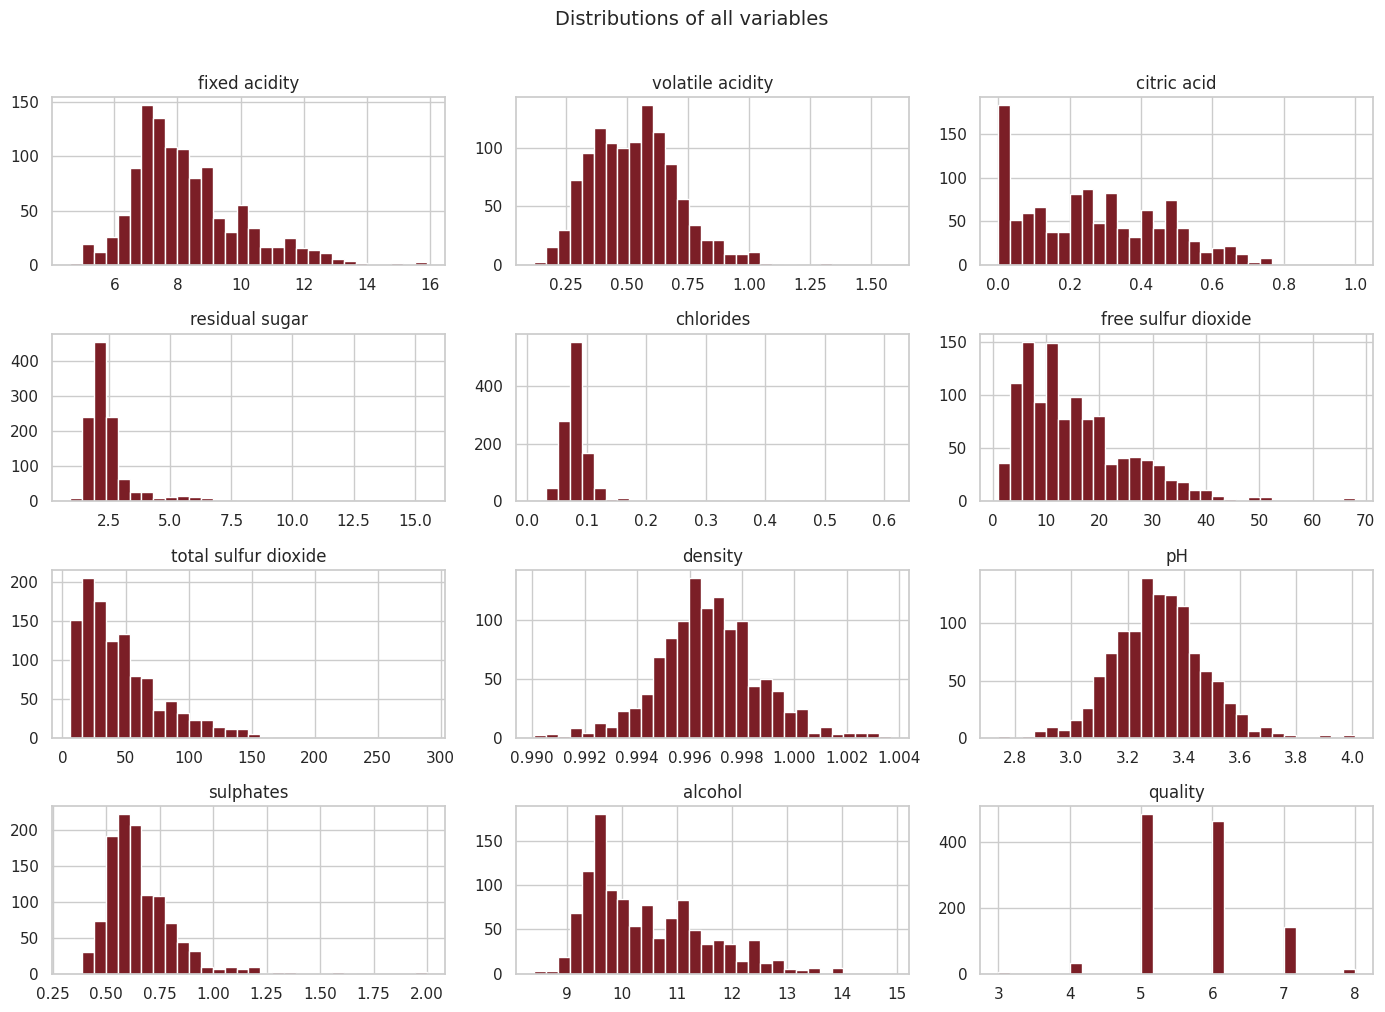

In [8]:
axes = df.hist(bins=30, figsize=(14, 10), color="#7b1e26", edgecolor="white")
plt.suptitle("Distributions of all variables", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation:** Density and pH look like nice bell curves. Residual sugar, chlorides and sulphates are very different: most values are small but there is a long tail to the right, meaning a few wines are much sweeter or saltier than the rest. Citric acid has a big spike at 0 because many wines simply don't contain any. Alcohol is also a bit right-skewed.

### 4.2 Boxplots

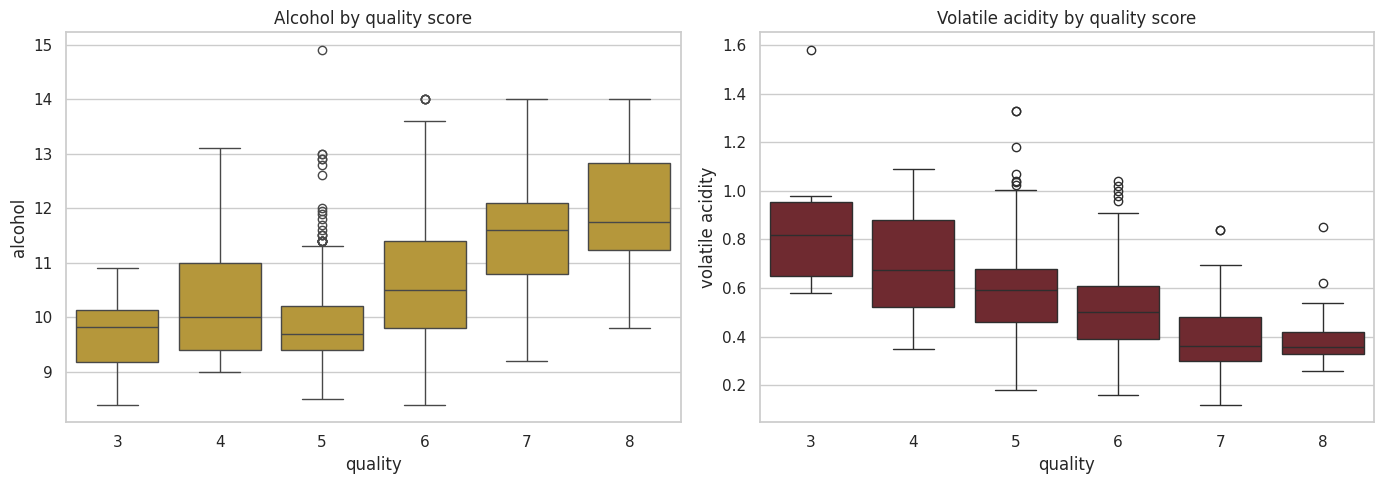

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="quality", y="alcohol", ax=axes[0], color="#c9a227")
axes[0].set_title("Alcohol by quality score")
sns.boxplot(data=df, x="quality", y="volatile acidity", ax=axes[1], color="#7b1e26")
axes[1].set_title("Volatile acidity by quality score")
plt.tight_layout()
plt.show()

**Interpretation:** These two plots show opposite trends:
- Alcohol goes up with quality. Better wines clearly contain more alcohol on average.
- Volatile acidity goes down with quality. This makes sense, because volatile acidity is basically the vinegar smell in wine - too much of it is considered a fault.

There are still lots of outliers in every quality level though, so chemistry alone doesn't decide the score.

### 4.3 Scatter plots

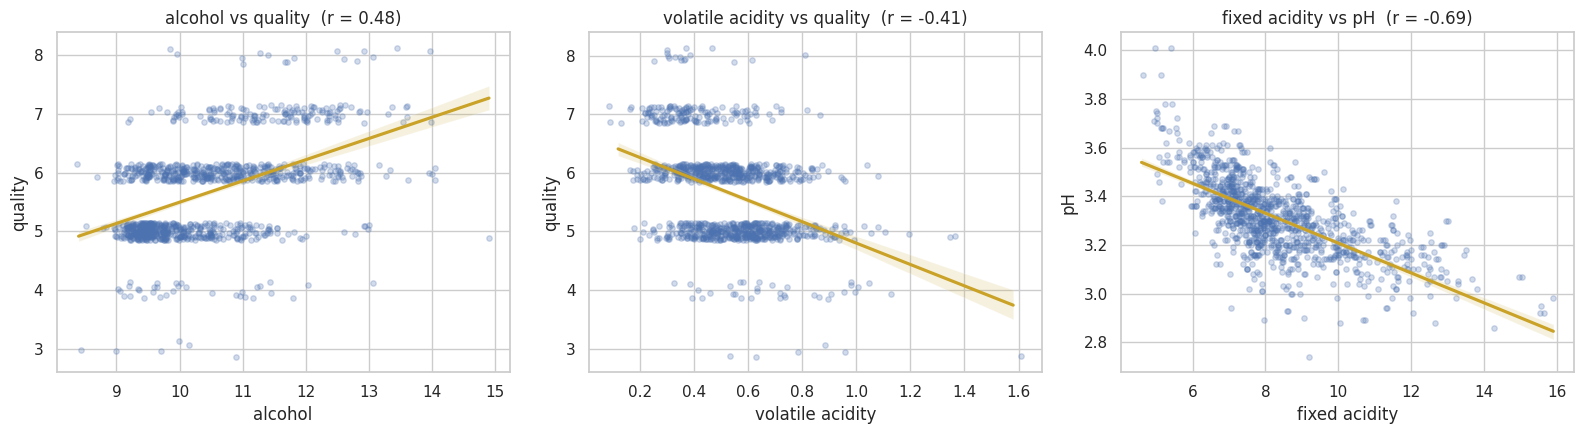

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [("alcohol", "quality"), ("volatile acidity", "quality"), ("fixed acidity", "pH")]
for ax, (x, y) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.25, "s": 15},
                line_kws={"color": "#c9a227"},
                x_jitter=0.05, y_jitter=0.15 if y == "quality" else 0)
    r = df[x].corr(df[y])
    ax.set_title(f"{x} vs {y}  (r = {r:.2f})")
plt.tight_layout()
plt.show()

**Interpretation:**
- Alcohol vs quality (r = 0.49): there is a visible upward trend. This is the strongest single relationship with quality in the whole dataset.
- Volatile acidity vs quality (r = -0.41): clear downward trend, same message as the boxplot.
- Fixed acidity vs pH (r = -0.69): more acid means lower pH. This is expected from chemistry, so it's a good sign that the data makes sense.

## 5. Distribution and skewness analysis

In [11]:
skew_kurt = pd.DataFrame({
    "skewness": df.skew(),
    "excess_kurtosis": df.kurtosis()
}).sort_values("skewness", ascending=False)
skew_kurt

,skewness,excess_kurtosis
chlorides,6.026,47.078
residual sugar,4.361,27.675
sulphates,2.497,12.017
total sulfur dioxide,1.666,5.099
free sulfur dioxide,1.231,1.932
fixed acidity,1.045,1.385
alcohol,0.863,0.221
volatile acidity,0.682,1.376
citric acid,0.372,-0.715
quality,0.287,0.315


In [12]:
# Formal normality check (Shapiro-Wilk) on selected variables
for col in ["density", "pH", "alcohol", "chlorides"]:
    stat, p = stats.shapiro(df[col])
    verdict = "≈ normal" if p > 0.05 else "NOT normal"
    print(f"{col:<12} W={stat:.3f}  p={p:.2e}  → {verdict}")

density      W=0.991  p=1.25e-06  → NOT normal
pH           W=0.992  p=8.67e-06  → NOT normal
alcohol      W=0.929  p=7.52e-23  → NOT normal
chlorides    W=0.469  p=1.03e-49  → NOT normal


**Interpretation:** Chlorides (skew = 6.0) and residual sugar (skew = 4.4) are extremely right-skewed. Most wines have low values and a small number of outliers stretch the tail. If we wanted to build a model later, a log transformation of these columns would probably help.

Density (0.10) and pH (0.22) are almost symmetric. Interestingly, the Shapiro-Wilk test still says they are "not normal" - but with 1143 samples the test picks up even tiny deviations, so in practice these two can be treated as approximately normal.

## 6. Correlation analysis

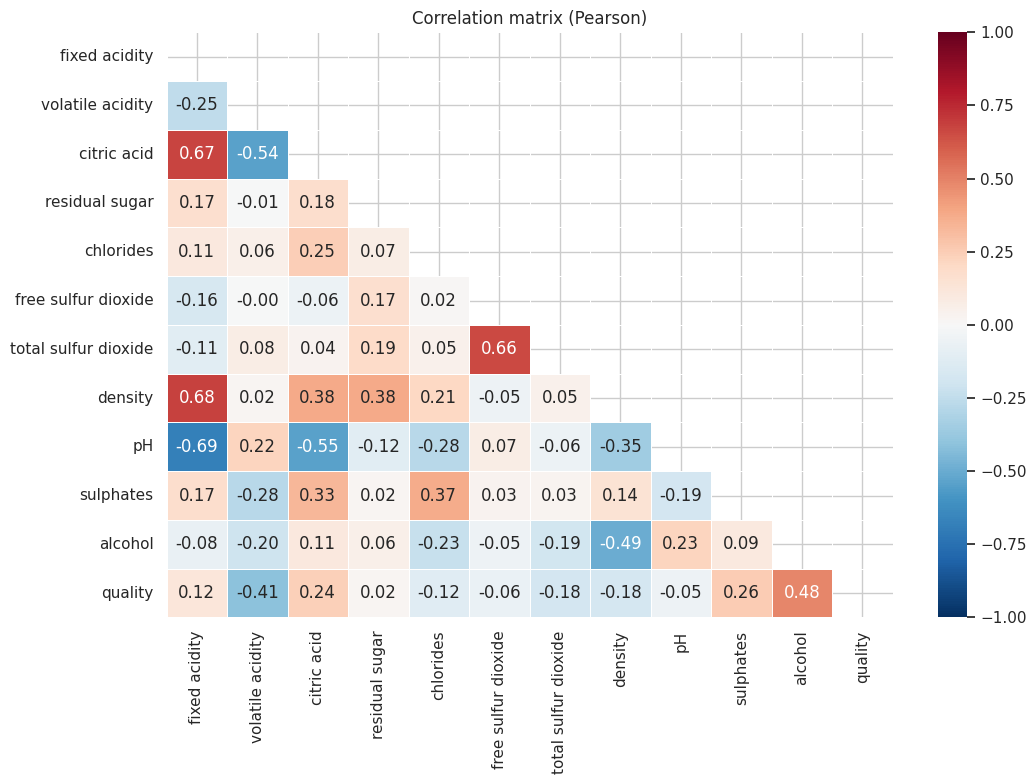

In [13]:
corr = df.corr()
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation matrix (Pearson)")
plt.tight_layout()
plt.show()

In [14]:
corr["quality"].drop("quality").sort_values(ascending=False)

alcohol                 0.485
sulphates               0.258
citric acid             0.241
fixed acidity           0.122
residual sugar          0.022
pH                     -0.052
free sulfur dioxide    -0.063
chlorides              -0.124
density                -0.175
total sulfur dioxide   -0.183
volatile acidity       -0.407
Name: quality, dtype: float64

**Interpretation:**

What correlates with quality:
- Alcohol (+0.48) and volatile acidity (-0.41) are clearly the two most important variables. Sulphates (+0.26) and citric acid (+0.24) help a little. Everything else is weak.
- No single variable has a correlation above 0.5 with quality, so quality depends on a combination of factors, not one magic ingredient.

Correlations between the chemical variables themselves:
- Fixed acidity and pH (-0.69): more acid = lower pH, which is just chemistry.
- Fixed acidity and density (+0.68), fixed acidity and citric acid (+0.67), free and total SO2 (+0.66): all of these are expected because the variables partly measure the same thing.

Two things to keep in mind: correlation only measures linear relationships, and correlation is not causation. Higher alcohol probably comes from riper grapes, and ripe grapes improve the wine in many ways at once.

## 7. Hypothesis test 1 - t-test (2 groups)

**Question:** Do good wines (quality 6 or higher) have more alcohol than poor wines (quality 5 or lower)?

- H0: the mean alcohol is the same in both groups
- H1: the means are different
- I use Welch's t-test (it doesn't assume equal variances), with alpha = 0.05.

In [15]:
low_q  = df.loc[df["quality"] <= 5, "alcohol"]
high_q = df.loc[df["quality"] >= 6, "alcohol"]

print(f"Poor wines (q≤5): n={len(low_q)},  mean={low_q.mean():.2f}%,  sd={low_q.std():.2f}")
print(f"Good wines (q≥6): n={len(high_q)}, mean={high_q.mean():.2f}%,  sd={high_q.std():.2f}")

t_stat, p_val = stats.ttest_ind(high_q, low_q, equal_var=False)

# Effect size: Cohen's d (pooled SD)
n1, n2 = len(high_q), len(low_q)
pooled_sd = np.sqrt(((n1-1)*high_q.var() + (n2-1)*low_q.var()) / (n1+n2-2))
cohens_d = (high_q.mean() - low_q.mean()) / pooled_sd

print(f"\nWelch t = {t_stat:.2f},  p = {p_val:.2e}")
print(f"Cohen's d = {cohens_d:.2f}")

Poor wines (q≤5): n=522,  mean=9.92%,  sd=0.78
Good wines (q≥6): n=621, mean=10.88%,  sd=1.11

Welch t = 17.07,  p = 3.71e-58
Cohen's d = 0.98


**Interpretation:** Good wines have on average 10.9% alcohol vs 9.9% for poor wines. The p-value is around 10^-58, which is way below 0.05, so we reject H0 - the difference is definitely not random.

I also calculated Cohen's d = 1.0, which counts as a large effect. This is worth mentioning because with more than 1100 samples, even a tiny meaningless difference would come out as "significant". Here the difference is both significant AND actually big.

## 8. Hypothesis test 2 - one-way ANOVA (3 groups)

- H0: all three group means are equal
- H1: at least one group is different
- One-way ANOVA with alpha = 0.05, and afterwards Tukey's HSD test to find out which groups actually differ.

In [16]:
df["quality_group"] = pd.cut(df["quality"], bins=[2, 4, 6, 8],
                             labels=["low (3-4)", "medium (5-6)", "high (7-8)"])

print(df.groupby("quality_group", observed=True)["alcohol"]
        .agg(["count", "mean", "std"]).round(2))

groups = [g["alcohol"].values for _, g in df.groupby("quality_group", observed=True)]
F, p_anova = stats.f_oneway(*groups)
print(f"\nANOVA: F = {F:.2f},  p = {p_anova:.2e}")

# Levene's test for equal variances (ANOVA assumption)
lev_stat, lev_p = stats.levene(*groups)
print(f"Levene's test for equal variances: p = {lev_p:.3f}")

               count   mean   std
quality_group                    
low (3-4)         39  10.17  1.02
medium (5-6)     945  10.27  0.99
high (7-8)       159  11.53  1.01

ANOVA: F = 111.18,  p = 7.73e-45
Levene's test for equal variances: p = 0.695


In [17]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(df["alcohol"], df["quality_group"].astype(str), alpha=0.05)
print(tukey)

     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1      group2    meandiff p-adj   lower   upper  reject
--------------------------------------------------------------
high (7-8)    low (3-4)  -1.3553    0.0 -1.7708 -0.9398   True
high (7-8) medium (5-6)   -1.258    0.0 -1.4573 -1.0587   True
 low (3-4) medium (5-6)   0.0974 0.8194 -0.2826  0.4773  False
--------------------------------------------------------------


/tmp/ipykernel_529/3264270871.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="quality_group", y="alcohol",


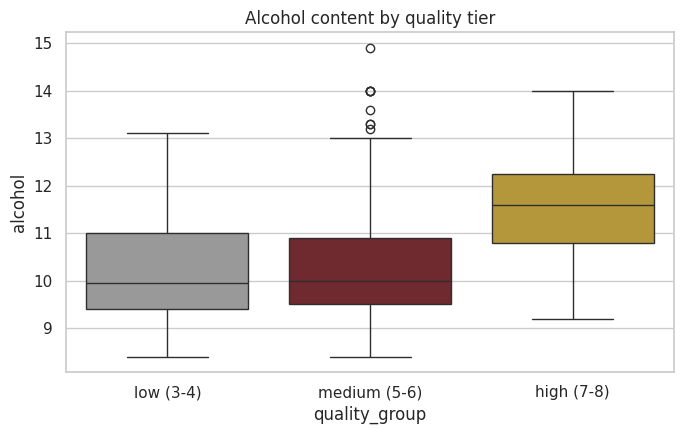

In [18]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="quality_group", y="alcohol",
            palette=["#999999", "#7b1e26", "#c9a227"])
plt.title("Alcohol content by quality tier")
plt.tight_layout()
plt.show()

**Interpretation:** F = 111 with p around 10^-45, so we reject H0: the groups don't all have the same mean alcohol.

But ANOVA only tells us that *some* difference exists. The Tukey test shows where it is: the high quality group (11.5% alcohol on average) is significantly different from both other groups, but low (10.2%) and medium (10.3%) are NOT significantly different from each other.

So alcohol separates the really good wines from the rest, but it can't tell a bad wine from an average one. For that, volatile acidity works better (see the boxplots in section 4.2).

Small caveat: Levene's test shows the variances aren't equal and the group sizes are very different (39 vs 945 vs 159), so the p-value shouldn't be taken as exact. But the result is so strong that the conclusion doesn't change.

## 9. Conclusions

1. The dataset is clean: 1143 wines, no missing values, no duplicates.
2. Most chemical variables are right-skewed, chlorides and residual sugar extremely so. Density and pH are close to normal.
3. What makes a good wine (in this data): more alcohol and less volatile acidity. Sulphates and citric acid help a bit. No single variable explains quality on its own.
4. The alcohol difference between good and poor wines is statistically significant and also large in practice (Cohen's d = 1.0). The ANOVA shows alcohol mainly separates the top wines from everyone else.
5. Limitations: quality is a subjective score, the quality groups are very unbalanced, and correlation doesn't prove causation.